# 🤖 09 · 统计学习基础（偏差-方差 / 交叉验证 / 正则化）

> 统计学与机器学习的交汇：从"解释数据"到"预测未来"。
> 本节讲三个统计学习核心概念：**偏差-方差权衡**、**交叉验证**、
> **正则化（L1/L2）**，以及分类评估（混淆矩阵/AUC/ROC）。

## 📋 本节要解决的问题

- 过拟合与欠拟合的本质是什么？偏差-方差怎么分解？
- 交叉验证为什么比"留出测试集"更稳？K 折怎么选？
- L1 与 L2 正则化的区别与稀疏性
- 分类评估：准确率/精确率/召回率/F1/AUC 怎么算？

## 📖 论文配图：从偏差-方差 U 形到"双下降"风险曲线

> **图源**：Belkin M, Hsu D, Ma S & Mandal S (2019) *Reconciling modern machine-learning practice and the classical bias-variance trade-off*, PNAS 116(32):15849–15854（开放获取）图 2。

![从偏差-方差 U 形到"双下降"风险曲线](../figures/double_descent_fig02.jpg)

> **怎么读这张图**：横轴为模型复杂度（参数量），纵轴为测试风险。经典偏差-方差权衡给出 U 形曲线；双下降现象则显示：模型复杂度继续增大越过"插值阈值"后，测试风险会再次下降。本节的偏差-方差权衡是 U 形部分；双下降是现代深度学习对经典理论的扩展。


## 📖 论文配图：ROC 曲线：灵敏度与特异度的权衡

> **图源**：Gönen M (2013) *Mixtures of receiver operating characteristic curves*, Academic Radiology 20(7)（开放获取）图 2。

![ROC 曲线：灵敏度与特异度的权衡](../figures/roc_pancreatic.jpg)

> **怎么读这张图**：以头外伤预后标志物为例的 ROC 曲线：横轴 1−特异度、纵轴灵敏度。曲线越靠近左上角，分类器区分能力越强；AUC = 曲线下面积。与本节 §4 的 ROC-AUC 讲解对应：阈值移动就是在曲线上滑动工作点。


## 1️⃣ 偏差-方差权衡（统计学习第一定律）

泛化误差 = 偏差² + 方差 + 不可约噪声
- **偏差**：模型过于简单（欠拟合），系统性偏离真值
- **方差**：模型过于复杂（过拟合），对训练集的波动敏感

> **面试**：怎么降低方差？→ 更多数据、正则化、集成（bagging）；
> 怎么降低偏差？→ 更复杂的模型、更多特征。两者此消彼长。

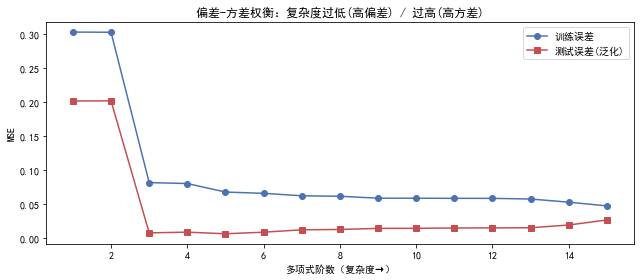

→ 测试误差呈 U 型：中间阶数最优（偏差方差平衡点）


In [1]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

# 模拟：不同复杂度模型拟合同一个带噪声的真函数
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline

rng = np.random.RandomState(10)
x = np.linspace(0, 1, 60)[:, None]
y_true = np.sin(2 * np.pi * x).ravel()
y = y_true + rng.normal(0, 0.3, 60)

train_errors, test_errors = [], []
x_test = np.linspace(0, 1, 300)[:, None]
y_test_true = np.sin(2 * np.pi * x_test).ravel()
for deg in range(1, 16):
    model = make_pipeline(PolynomialFeatures(deg), LinearRegression())
    model.fit(x, y)
    train_errors.append(np.mean((model.predict(x) - y) ** 2))
    test_errors.append(np.mean((model.predict(x_test) - y_test_true) ** 2))

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(range(1, 16), train_errors, 'o-', color='#4C72B0', label='训练误差')
ax.plot(range(1, 16), test_errors, 's-', color='#C44E52', label='测试误差(泛化)')
ax.set_xlabel('多项式阶数（复杂度→）'); ax.set_ylabel('MSE')
ax.set_title('偏差-方差权衡：复杂度过低(高偏差) / 过高(高方差)')
ax.legend()
plt.tight_layout()
plt.show()
print('→ 测试误差呈 U 型：中间阶数最优（偏差方差平衡点）')

## 2️⃣ K 折交叉验证

把训练数据分成 K 份，轮流拿 1 份做验证、其余 K-1 份训练，K 次平均。
- K=5/10 常见；K 越大验证集越足、但计算量越大
- **为什么比单次留出稳**：每个样本都被验证一次，方差小，防"运气切分"

> **面试**：什么时候用留一法（LOO）？→ 数据量小、追求无偏（LOO = K=n，
> 但方差高、计算贵）。

In [2]:
from sklearn.model_selection import cross_val_score, KFold
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline

rng = np.random.RandomState(12)
x = np.linspace(0, 1, 80)[:, None]
y = np.sin(2 * np.pi * x).ravel() + rng.normal(0, 0.3, 80)

for deg in [1, 3, 8]:
    model = make_pipeline(PolynomialFeatures(deg), LinearRegression())
    scores = cross_val_score(model, x, y, cv=5, scoring='neg_mean_squared_error')
    print('阶数 %d: 5折CV RMSE=%.4f (±%.4f)' % (deg, (-scores.mean())**0.5, scores.std()**0.5))
print('→ 阶数 3 的 CV 误差最小（偏差-方差平衡）')

阶数 1: 5折CV RMSE=0.6648 (±0.4348)
阶数 3: 5折CV RMSE=0.4337 (±0.3705)
阶数 8: 5折CV RMSE=20.8038 (±28.8222)
→ 阶数 3 的 CV 误差最小（偏差-方差平衡）


## 3️⃣ 正则化：L1（Lasso）与 L2（Ridge）

在原损失上加惩罚项：
- **Ridge (L2)**：$\min ||y-X\beta||^2 + \lambda||\beta||^2$ —— 系数整体收缩
- **Lasso (L1)**：$\min ||y-X\beta||^2 + \lambda||\beta||_1$ —— 有**特征选择**（系数压到 0）

> **面试**：L1 为什么产生稀疏解？→ L1 惩罚面是菱形，最优解常落在坐标轴上
> （某些系数恰为 0）；L2 是圆形，系数平滑收缩但不为 0。

In [3]:
import numpy as np
from sklearn.linear_model import Ridge, Lasso

rng = np.random.RandomState(15)
n, p = 100, 20
X = rng.normal(0, 1, (n, p))
# 只有前 3 个特征真实有效
beta_true = np.zeros(p); beta_true[:3] = [2.0, -1.5, 1.0]
y = X @ beta_true + rng.normal(0, 0.5, n)

alphas = [1e-3, 1.0, 10.0]
for a in alphas:
    ridge = Ridge(alpha=a).fit(X, y)
    lasso = Lasso(alpha=a).fit(X, y)
    nz_r = np.sum(np.abs(ridge.coef_) > 1e-6)
    nz_l = np.sum(np.abs(lasso.coef_) > 1e-6)
    print('α=%-5s Ridge 非零系数=%2d  Lasso 非零系数=%2d' % (a, nz_r, nz_l))
print('→ Lasso 在 α 较大时把无关特征系数压成 0（稀疏）✅')

α=0.001 Ridge 非零系数=20  Lasso 非零系数=20
α=1.0   Ridge 非零系数=20  Lasso 非零系数= 2
α=10.0  Ridge 非零系数=20  Lasso 非零系数= 0
→ Lasso 在 α 较大时把无关特征系数压成 0（稀疏）✅


## 4️⃣ 分类评估：混淆矩阵 / PR / ROC-AUC

四格表：TP / FP / FN / TN
- **精确率** Precision = TP/(TP+FP)：预测正例中真比例
- **召回率** Recall = TP/(TP+FN)：真正例中被抓出比例
- **F1** = 2PR/(P+R)：调和平均
- **AUC**：ROC 曲线下面积，随机模型 0.5，完美 1.0；与阈值无关

> **面试**：什么时候重精确率、什么时候重召回率？
> → 垃圾邮件（误杀代价高）重精确率；癌症筛查（漏诊代价高）重召回率。

In [4]:
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support, roc_auc_score, roc_curve

rng = np.random.RandomState(20)
y_true = np.array([0]*80 + [1]*20)
y_score = np.concatenate([rng.uniform(0, .6, 80), rng.uniform(.4, 1, 20)])
y_pred = (y_score > 0.5).astype(int)

cm = confusion_matrix(y_true, y_pred)
print('混淆矩阵:\n', cm)
p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average='binary', pos_label=1)
print('Precision=%.3f Recall=%.3f F1=%.3f' % (p, r, f1))
auc = roc_auc_score(y_true, y_score)
print('AUC=%.3f' % auc)
assert 0.7 < auc < 1.0
print('✅ 分类评估指标完成')

混淆矩阵:
 [[71  9]
 [ 7 13]]
Precision=0.591 Recall=0.650 F1=0.619
AUC=0.934
✅ 分类评估指标完成


## 5️⃣ 面试实战：统计学习速答

> **题**：训练集准确率 99%、测试 60%，怎么办？
> 答：过拟合——加正则/更多数据/降复杂度/交叉验证调参。

> **题**：AUC 与准确率选哪个？→ 不平衡数据用 AUC（阈值无关）；
> 业务上更关心具体阈值行为时用 PR 曲线（AUC 对类别不平衡不太敏感，PR 更敏感）。

> **题**：L1 与 L2 能同时用吗？→ 能（Elastic Net），兼备稀疏与平滑。

In [5]:
print('速答完成：')
print('  过拟合 → 正则化/更多数据/降复杂度')
print('  不平衡 → AUC / PR 曲线')
print('  L1+L2 → Elastic Net')
print('✅ 统计学习面试速答清单')

速答完成：
  过拟合 → 正则化/更多数据/降复杂度
  不平衡 → AUC / PR 曲线
  L1+L2 → Elastic Net
✅ 统计学习面试速答清单


## 🧮 手算示例：混淆矩阵四率逐步算

> **混淆矩阵**：预测 vs 真实，TP=50, FP=10, FN=5, TN=35（共 100）

**① 准确率**：$\frac{TP+TN}{N} = \frac{50+35}{100} = 0.85$

**② 精确率**：$\frac{TP}{TP+FP} = \frac{50}{50+10} = \frac{50}{60} \approx 0.8333$

**③ 召回率**：$\frac{TP}{TP+FN} = \frac{50}{50+5} = \frac{50}{55} \approx 0.9091$

**④ F1**：$\frac{2PR}{P+R} = \frac{2\times0.8333\times0.9091}{1.7424} \approx 0.8696$$

In [6]:
import numpy as np
TP, FP, FN, TN = 50, 10, 5, 35
acc = (TP+TN)/(TP+FP+FN+TN)
prec = TP/(TP+FP)
rec = TP/(TP+FN)
f1 = 2*prec*rec/(prec+rec)
print('准确率(手算=0.85) =', round(acc, 4))
print('精确率(手算≈0.8333) =', round(prec, 4))
print('召回率(手算≈0.9091) =', round(rec, 4))
print('F1(手算≈0.8696) =', round(f1, 4))
from sklearn.metrics import precision_recall_fscore_support
# 构造与手算等效的 y_true / y_pred（混淆矩阵 TP=50 FP=10 FN=5 TN=35）
y_true = np.array([1]*55 + [0]*45)
y_pred = np.zeros(100, dtype=int)
y_pred[:50] = 1      # 前 50 个真实正例预测为正 → TP=50
y_pred[50:55] = 0    # 索引 50-54 真实正例漏掉 → FN=5
y_pred[55:65] = 1    # 索引 55-64 真实负例误判 → FP=10
y_pred[65:] = 0      # 索引 65-99 真实负例 → TN=35
p_s, r_s, f_s, _ = precision_recall_fscore_support(y_true, y_pred, average='binary', pos_label=1)
print('sklearn 对照: P=%.4f R=%.4f F1=%.4f' % (p_s, r_s, f_s))
assert abs(prec-p_s) < 1e-9 and abs(rec-r_s) < 1e-9 and abs(f1-f_s) < 1e-9
print('✅ 手算与 sklearn 一致')

准确率(手算=0.85) = 0.85
精确率(手算≈0.8333) = 0.8333
召回率(手算≈0.9091) = 0.9091
F1(手算≈0.8696) = 0.8696
sklearn 对照: P=0.8333 R=0.9091 F1=0.8696
✅ 手算与 sklearn 一致


## ✅ 自测清单

- [ ] 能解释偏差-方差分解并用实验演示 U 型误差
- [ ] 能手写/解释 K 折交叉验证
- [ ] 能讲清 L1 稀疏性与 L2 平滑性的几何直觉
- [ ] 能算混淆矩阵四率与 F1、AUC
- [ ] 能解决"过拟合怎么办"类面试题